In [1]:
%load_ext lab_black

import pandas as pd
import numpy as np
import polars as pl
from tqdm import tqdm
import os
import gc
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import warnings

warnings.filterwarnings("ignore")

pd.set_option("max_rows", 500)

%matplotlib inline

In [2]:
catalog.exists("sample_submission")

True

In [3]:
catalog.exists("df_train"), catalog.exists("df_test")

(True, True)

In [4]:
%%time

df_train = catalog.load("df_train")
df_test = catalog.load("df_test")

df_train.name = "df_train"
df_test.name = "df_test"

def make_date_stats(df):
    df['date'] = pd.to_datetime(df["ts"] * 1e6)
    df['day'] = df['date'].dt.day
    df['dayofweek'] = df['date'].dt.dayofweek
    df['hour'] = df['date'].dt.hour
    return df

df_train = make_date_stats(df_train)
df_test = make_date_stats(df_test)

# df_train = pl.from_pandas(df_train)
# df_test = pl.from_pandas(df_test)

                    INFO     Loading data from 'df_train' (ParquetDataSet)...                   ]8;id=448951;file:///media/mikhail/disk/ML/compet/kaggle/otto-recommender-system/venv_otto/lib/python3.7/site-packages/kedro/io/data_catalog.py\data_catalog.py]8;;\:]8;id=357022;file:///media/mikhail/disk/ML/compet/kaggle/otto-recommender-system/venv_otto/lib/python3.7/site-packages/kedro/io/data_catalog.py#344\344]8;;\

[12/05/22 09:25:11] INFO     Loading data from 'df_test' (ParquetDataSet)...                    ]8;id=154870;file:///media/mikhail/disk/ML/compet/kaggle/otto-recommender-system/venv_otto/lib/python3.7/site-packages/kedro/io/data_catalog.py\data_catalog.py]8;;\:]8;id=458640;file:///media/mikhail/disk/ML/compet/kaggle/otto-recommender-system/venv_otto/lib/python3.7/site-packages/kedro/io/data_catalog.py#344\344]8;;\

CPU times: user 1min 6s, sys: 22.8 s, total: 1min 29s
Wall time: 1min 7s


In [5]:
df_train

,user,aid,ts,type,n_session,date,day,dayofweek,hour
0,0,1517085,1659304800025,clicks,0,2022-07-31 22:00:00.024999936,31,6,22
1,0,1563459,1659304904511,clicks,0,2022-07-31 22:01:44.511000064,31,6,22
2,0,1309446,1659367439426,clicks,1,2022-08-01 15:23:59.425999872,1,0,15
3,0,16246,1659367719997,clicks,1,2022-08-01 15:28:39.996999936,1,0,15
4,0,1781822,1659367871344,clicks,1,2022-08-01 15:31:11.344000000,1,0,15
...,...,...,...,...,...,...,...,...,...
216716091,12899776,1737908,1661723987073,clicks,0,2022-08-28 21:59:47.072999936,28,6,21
216716092,12899777,384045,1661723976974,clicks,0,2022-08-28 21:59:36.974000128,28,6,21
216716093,12899777,384045,1661723986800,clicks,0,2022-08-28 21:59:46.800000000,28,6,21
216716094,12899778,561560,1661723983611,clicks,0,2022-08-28 21:59:43.611000064,28,6,21


In [6]:
df_test

,user,aid,ts,type,n_session,date,day,dayofweek,hour
0,12899779,59625,1661724000278,clicks,0,2022-08-28 22:00:00.278000128,28,6,22
1,12899780,1142000,1661724000378,clicks,0,2022-08-28 22:00:00.377999872,28,6,22
2,12899780,582732,1661724058352,clicks,0,2022-08-28 22:00:58.352000000,28,6,22
3,12899780,973453,1661724109199,clicks,0,2022-08-28 22:01:49.199000064,28,6,22
4,12899780,736515,1661724136868,clicks,0,2022-08-28 22:02:16.868000000,28,6,22
...,...,...,...,...,...,...,...,...,...
6928118,14571577,1141710,1662328774770,clicks,0,2022-09-04 21:59:34.769999872,4,6,21
6928119,14571578,519105,1662328775009,clicks,0,2022-09-04 21:59:35.008999936,4,6,21
6928120,14571579,739876,1662328775605,clicks,0,2022-09-04 21:59:35.604999936,4,6,21
6928121,14571580,202353,1662328781067,clicks,0,2022-09-04 21:59:41.067000064,4,6,21


In [7]:
df_train["type"].value_counts()

clicks    194720954
carts      16896191
orders      5098951
Name: type, dtype: int64

In [8]:
df_train["date"].min(), df_train["date"].max()

(Timestamp('2022-07-31 22:00:00.024999936'), Timestamp('2022-08-28 21:59:59.984000'))

In [9]:
df_test["date"].min(), df_test["date"].max()

(Timestamp('2022-08-28 22:00:00.278000128'), Timestamp('2022-09-04 21:59:51.563000064'))

In [10]:
%%time

df_train.groupby(['dayofweek', 'type'])[['ts']].count()

CPU times: user 15.9 s, sys: 8.91 s, total: 24.8 s
Wall time: 24.4 s


ts 
 
 
 dayofweek 
 type 
 
 
 
 
 
 0 
 carts 
 2332060 
 
 
 clicks 
 27433403 
 
 
 orders 
 735671 
 
 
 1 
 carts 
 2442042 
 
 
 clicks 
 27219139 
 
 
 orders 
 784725 
 
 
 2 
 carts 
 2347260 
 
 
 clicks 
 26809296 
 
 
 orders 
 701500 
 
 
 3 
 carts 
 2215700 
 
 
 clicks 
 25669592 
 
 
 orders 
 648017 
 
 
 4 
 carts 
 2283406 
 
 
 clicks 
 26344845 
 
 
 orders 
 660618 
 
 
 5 
 carts 
 2336674 
 
 
 clicks 
 27444852 
 
 
 orders 
 666279 
 
 
 6 
 carts 
 2939049 
 
 
 clicks 
 33799827 
 
 
 orders 
 902141

In [11]:
%%time

df_test.groupby(['dayofweek', 'type'])[['ts']].count()

CPU times: user 482 ms, sys: 192 ms, total: 674 ms
Wall time: 673 ms


ts 
 
 
 dayofweek 
 type 
 
 
 
 
 
 0 
 carts 
 87833 
 
 
 clicks 
 930154 
 
 
 orders 
 13618 
 
 
 1 
 carts 
 85000 
 
 
 clicks 
 963438 
 
 
 orders 
 10897 
 
 
 2 
 carts 
 87349 
 
 
 clicks 
 946720 
 
 
 orders 
 10714 
 
 
 3 
 carts 
 76894 
 
 
 clicks 
 835907 
 
 
 orders 
 8658 
 
 
 4 
 carts 
 68203 
 
 
 clicks 
 759088 
 
 
 orders 
 7094 
 
 
 5 
 carts 
 73643 
 
 
 clicks 
 859025 
 
 
 orders 
 6649 
 
 
 6 
 carts 
 91089 
 
 
 clicks 
 998300 
 
 
 orders 
 7850

In [12]:
def plot_n_interactions_per_dayofweek(df):
    try:
        df_name = df.name
    except AttributeError:
        df_name = None

    title = "n_interactions per dayofweek"
    if df_name is not None:
        title += f" in {df_name}"

    plt.figure(figsize=(12, 7))
    plt.title(title)
    plt.xlabel("dayofweek")
    plt.ylabel("n_interactions")

    dict_type_inter_offset = dict()
    dict_type_inter_offset["clicks"] = -0.2
    dict_type_inter_offset["carts"] = 0.0
    dict_type_inter_offset["orders"] = 0.2

    dict_type_inter_color = dict()
    dict_type_inter_color["clicks"] = "b"
    dict_type_inter_color["carts"] = "g"
    dict_type_inter_color["orders"] = "r"

    for (dayofweek, type_inter), df_cur in df.groupby(["dayofweek", "type"]):
        ys = df_cur["ts"].count()
        plt.bar(
            dayofweek + dict_type_inter_offset[type_inter],
            ys,
            width=0.2,
            color=dict_type_inter_color[type_inter],
            align="center",
            # label=feature,
            # marker=",",
            # linestyle="dashed",
            alpha=0.6,
        )

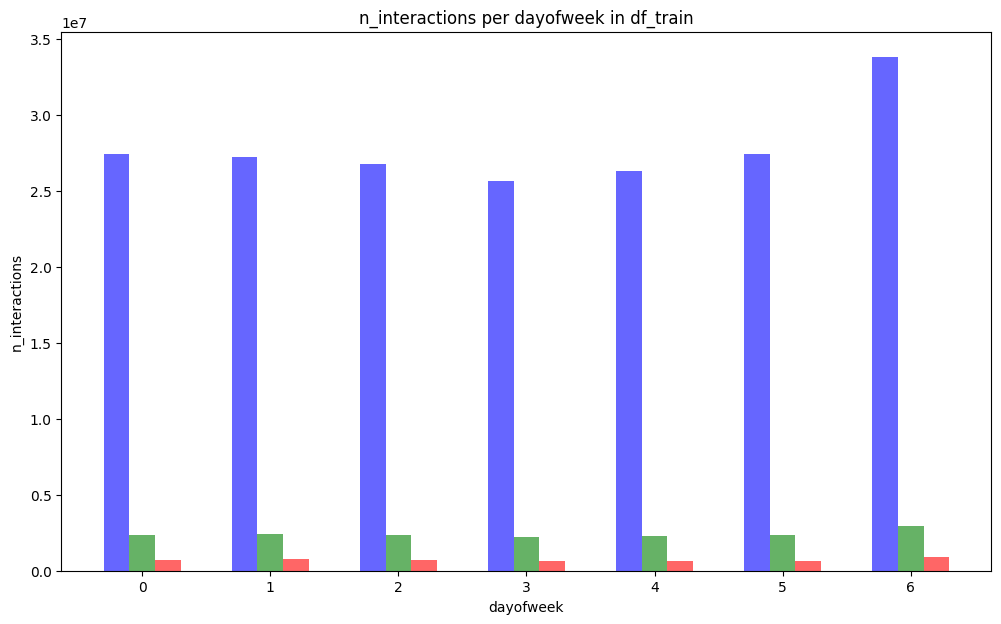

In [13]:
plot_n_interactions_per_dayofweek(df_train)

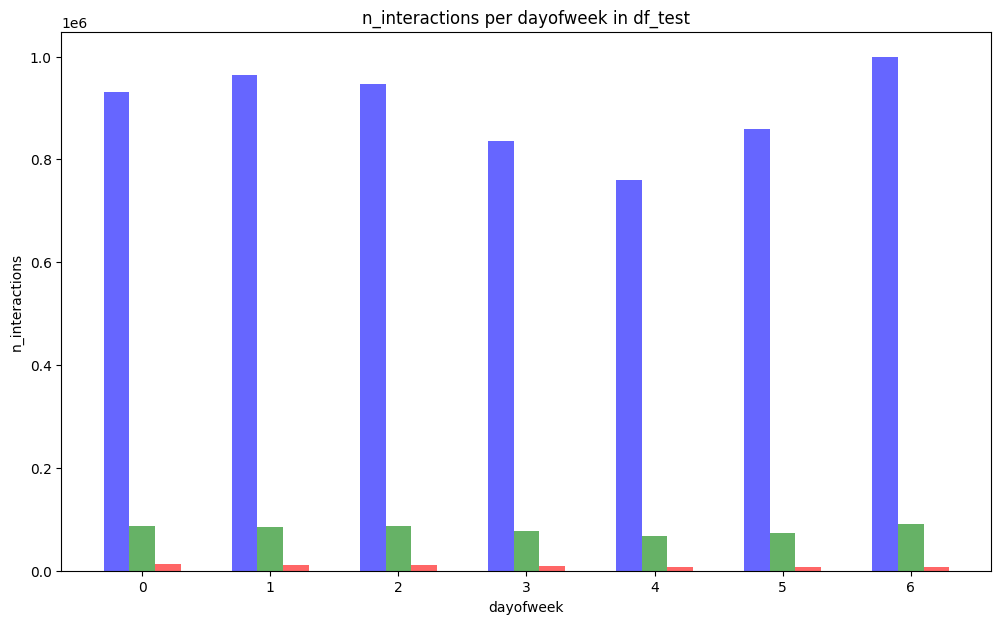

In [14]:
plot_n_interactions_per_dayofweek(df_test)